# Isothermal 0D Master Equation Simulation
### Import libraries

In [1]:
import os
import sys
import numpy as np
import pandas as pd

from tqdm.notebook import tqdm

Global paths

In [2]:
# Current Working Directory
CWD = os.getcwd()
# WORKSPACE
WORKSPACE = os.environ['WORKSPACE_PATH']

In [3]:
# SurQCT
SurQCT = WORKSPACE + '/ML/PyCOMET/pycomet/examples/SurQCT/'
sys.path.append(os.path.abspath(SurQCT))

from surqct.src.chemical_systems import chemical_systems as chem_sys
from surqct.src.postprocessing.MasterEquation import Plotting

Case-specific paths

In [4]:
# Output directory
out_dir = CWD + '/../Output/MasterEquation/'
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

### Initializing Runs

Global inputs

In [5]:
SystemName  = 'O3_UMN'
ProcBool    = [2,1,1,0]
TTranVec    = [5000, 10000, 20000]
CasesSuffix = {
    'QCT':        f'/QCT/{SystemName}/',
    'SurQCT-Ref': f'/SurQCT/{SystemName}/Inel/run.ref/',
    'SurQCT-C03': f'/SurQCT/{SystemName}/Inel/configs/config.03/run.03/',
    'SurQCT-C06': f'/SurQCT/{SystemName}/Inel/configs/config.06/run.03/'
}

#### Initialization

In [6]:
Data     = {k: {} for k in CasesSuffix.keys()}
ProcCode = "_".join(map(str, ProcBool))
out_dir  = out_dir + '/' + ProcCode
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

Chemical system

In [7]:
# Initializing system
System = chem_sys.get_system(SystemName, ProcBool)
# Initializing molecules
for Mol in System.Molecules:
    Mol.read_diatdata()
# Initializing Master Equation object
ME = System.MasterEquation

### Reading Master Equation Solution Files

In [8]:
for Temp in tqdm(TTranVec):
    Temp = int(Temp)
    print(f'\nReading data for temperature T = {Temp} K')
    for k in Data.keys():
        print(f'>> Reading 0D ME solution for {k}')
        Data[k][Temp]        = {}
        PathToCase_k         = CasesSuffix[k] + f'/T{str(Temp)}K/{ProcCode}/output_box/'
        Data[k][Temp]['box'] = ME.read_box(PathToCase_k)
        Data[k][Temp]['pop'] = ME.read_popevolution(PathToCase_k, TimeInstants=len(Data[k][Temp]['box']))

  0%|          | 0/3 [00:00<?, ?it/s]


Reading data for temperature T = 5000 K
>> Reading 0D ME solution for QCT
>> Reading 0D ME solution for SurQCT-Ref
>> Reading 0D ME solution for SurQCT-C03
>> Reading 0D ME solution for SurQCT-C06

Reading data for temperature T = 10000 K
>> Reading 0D ME solution for QCT
>> Reading 0D ME solution for SurQCT-Ref
>> Reading 0D ME solution for SurQCT-C03
>> Reading 0D ME solution for SurQCT-C06

Reading data for temperature T = 20000 K
>> Reading 0D ME solution for QCT
>> Reading 0D ME solution for SurQCT-Ref
>> Reading 0D ME solution for SurQCT-C03
>> Reading 0D ME solution for SurQCT-C06


### Computing
Energies

In [9]:
for Temp in tqdm(TTranVec):
    Temp = int(Temp)
    for k in Data.keys():
        Data[k][Temp]['E'] = ME.compute_energies(Ni=Data[k][Temp]['pop'])

  0%|          | 0/3 [00:00<?, ?it/s]

Taus

In [10]:
if ProcBool[0] == 0:
    for Temp in tqdm(TTranVec):
        Temp = int(Temp)
        for k in Data.keys():
            Data[k][Temp]['TausP'] = ME.compute_taus(Data[k][Temp]['box'], Data[k][Temp]['E'])

Mass depletion

In [11]:
if ProcBool[0] > 0:
    for Temp in tqdm(TTranVec):
        Temp = int(Temp)
        for k in Data.keys():
            Data[k][Temp]['XDepl'] = ME.compute_mass_depletion(Data[k][Temp]['box'])

  0%|          | 0/3 [00:00<?, ?it/s]

In [27]:

out_dir = CWD + '/../Output/MasterEquation/' + ProcCode + '.06'
if not os.path.exists(out_dir):
    os.makedirs(out_dir)

Keys = ['QCT', 'SurQCT-Ref', 'SurQCT-C06']#, 'SurQCT-C06']

Data_i = {k: Data[k] for k in Keys}

### Plotting
Energies

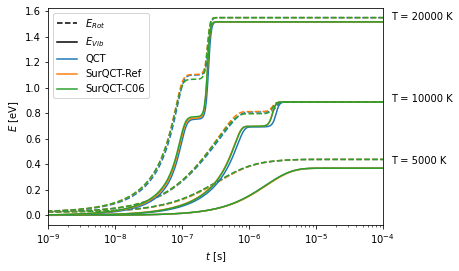

In [28]:
Plotting.energies(out_dir, System, Data_i, TTranVec)

Taus

In [29]:
if ProcBool[0] == 0:
    Plotting.taus(out_dir, System, Data_i, TTranVec)

Mole fraction

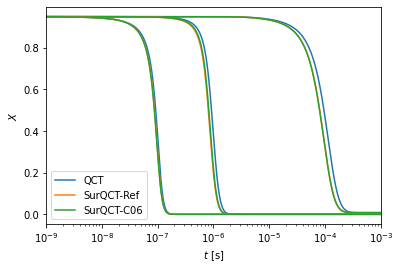

In [30]:
if ProcBool[0] > 0:
    Plotting.mole_fraction(out_dir, System, Data_i, TTranVec, xlim=[1.e-9, 1.e-3])

Mole fraction depletion delays

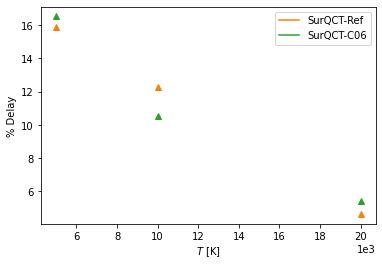

In [31]:
if ProcBool[0] > 0:
    Plotting.mole_depletion_delays(out_dir, System, Data_i, TTranVec)

Populations

In [17]:
TimeSamples = [1e-7, 5e-7, 1e-6, 5e-6]
TimeShots   = {int(k): TimeSamples for k in TTranVec}
# TimeShots   = {
#     1500:  TimeSamples,
#     5000:  TimeSamples,
#     10000: TimeSamples,
#     20000: TimeSamples
# }

In [18]:
# populations(out_dir, System, Data, TTranVec, TimeShots, subplots_shape=(2,2))

## 